# 02: Feature Selection

This notebook covers predictive power analysis, multicollinearity filtering, and exploratory XGBoost-based feature selection for both PD and LGD models. Its output is the final feature lists and the dataframe checkpoint used by the EDA notebooks.

**Input:** `data/processed/checkpoint_end_Data_Diagnosis.pkl`  
**Output:** `data/processed/checkpoint_DataFrame_for_EDA.pkl`, `data/processed/features_PD_for_EDA.pkl`, `data/processed/features_LGD_for_EDA.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import pickle
import os

from feature_selection import select_features, compute_plot_correlation_matrix, analyze_correlated_pairs, exploratory_feature_selection

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_end_Data_Diagnosis.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

# Feature selection uses the development sample only: matured loans, whose
# outcomes are fully observed (see 01_data_diagnosis, section 2.1).
dev = df_master_features[df_master_features["is_matured"] == 1]
dev_default = dev[dev["Target_Variable_Default"] == 1]

print(f"Loaded. Shape: {df_master_features.shape}")
print(f"Development sample: {len(dev):,} loans | {len(dev_default):,} defaulted")

Loaded. Shape: (2139643, 54)
Development sample: 676,113 loans | 100,589 defaulted


## 2. Define Feature Sets

PD and LGD models use different feature subsets. Two groups of variables are excluded from both sets from the start:

- **Post-origination variables** (payments, recoveries, late fees): they are outcomes, not borrower characteristics, and the LGD target is built from them.
- **Vintage-dependent variables**: ten credit-bureau fields that Lending Club only reports from late 2015 onwards. They are missing (or carry the 999 sentinel) for every loan issued up to 2014, for 95% of 2015 issues and for almost none from 2016. Their missingness tells a model how recent a loan is, which reintroduces the survival bias that excluding `issue_date_year` is meant to avoid, and they are empty in the matured development sample anyway.

For LGD, `EAD` is also excluded because it is the denominator of `Target_Variable_Loss`; `monthly_payment` carries the debt-burden signal instead.

In [4]:
# Variables observed after origination (payments, recoveries, late fees). They are
# outcomes, not borrower characteristics, and the LGD target is built from them,
# so they are excluded from both candidate sets from the start.
POST_ORIGINATION = [
    "princ_rec", "interest_rec", "remaining_princ_for_tot_amnt_fund",
    "paym_rec_for_tot_amnt_fund", "late_fees_rec_LGD", "has_late_fees_PD",
]

# Fields only reported from late 2015: their missingness encodes the vintage.
VINTAGE_DEPENDENT = [
    "max_bal_owed", "bal_to_cred_lim", "num_inq", "num_open_trades_in_6mths",
    "num_installment_acc_op_in_12mths", "num_installment_acc_op_in_24mths",
    "num_rev_trades_op_in_12mths", "num_rev_trades_op_in_24mths",
    "mths_since_last_installment_acc_op_PD", "mths_since_last_installment_acc_op_LGD",
]
NOT_FEATURES = ["is_matured"]   # development-sample flag, not a borrower attribute

# Evidence: share of missing or 999 values by issue year (all loans)
availability = pd.DataFrame({
    col: (df_master_features[col].isna() | (df_master_features[col] == 999))
         .groupby(df_master_features["issue_date_year"]).mean().mul(100).round(1)
    for col in VINTAGE_DEPENDENT
}).T
print("Share of missing or 999 values (%) by issue year")
print(availability.to_string())

EXCLUDED = set(POST_ORIGINATION + VINTAGE_DEPENDENT + NOT_FEATURES)

# PD features: exclude LGD-specific columns, the LGD target and the excluded groups
features_PD = [
    col for col in df_master_features.columns
    if not col.endswith('_LGD')
    and col != 'Target_Variable_Loss'
    and col not in EXCLUDED
]

# LGD features: exclude PD-specific columns, the PD target, EAD (the target's
# denominator; monthly_payment carries the debt-burden signal) and the excluded groups
features_LGD = [
    col for col in df_master_features.columns
    if not col.endswith('_PD')
    and col != 'Target_Variable_Default'
    and col != 'EAD'
    and col not in EXCLUDED
]

print(f"\nPD features: {len(features_PD)}")
print(f"LGD features: {len(features_LGD)}")

Share of missing or 999 values (%) by issue year
issue_date_year                          2007   2008   2009   2010   2011   2012   2013   2014  2015  2016  2017  2018
max_bal_owed                            100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
bal_to_cred_lim                         100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
num_inq                                 100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
num_open_trades_in_6mths                100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
num_installment_acc_op_in_12mths        100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
num_installment_acc_op_in_24mths        100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0
num_rev_trades_op_in_12mths             100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  95.0   0.0   0.0   0.0

## 3. Predictive Power Analysis

Three metrics are computed per feature: mutual information, permutation importance (via a fast Random Forest), and Lasso coefficients. Features are retained under a conservative AND criterion: a feature must show signal in at least two of the three methods. Boruta is run for PD only.

In [5]:
# PD: predictive power analysis with Boruta (development sample)
report_PD = select_features(
    df_features=dev[features_PD].drop(columns="Target_Variable_Default"),
    y=dev["Target_Variable_Default"],
    run_boruta=True,
    sample_size=500_000
)

with open("data/processed/report_PD_Model.pkl", "wb") as f:
    pickle.dump(report_PD, f)

→ Encoding features...


→ Sampling 500,000 rows from 676,113...


→ Computing mutual information...


→ Computing permutation importance (may take a few minutes)...


→ Computing L1 (Lasso) coefficients...


→ Running Boruta (may take several minutes)...



✓ Done.  Features kept: 30 | Discarded: 1


In [6]:
# Load PD report (skip re-running)
with open("data/processed/report_PD_Model.pkl", "rb") as f:
    report_PD = pickle.load(f)

report_PD

,feature,mutual_info,perm_importance,lasso_coef,boruta_support,discard
0,loan_term_months,0.077997,0.015128,0.114112,0,0
1,mths_since_recent_bankcard_delinq_PD,0.076554,0.002569,0.019669,0,0
2,mths_since_recent_revol_delinq_PD,0.074527,0.003088,0.020737,0,0
3,mths_since_last_delinq_PD,0.060336,0.006648,0.013917,0,0
4,initial_list_status,0.045871,0.000691,0.012972,0,0
5,home_ownership_status,0.044290,0.034354,0.103358,0,0
6,monthly_payment,0.039018,0.019268,0.250207,1,0
7,verification_status,0.034309,0.013697,0.038717,0,0
8,total_credit_revolving_bal,0.028164,0.022954,0.065204,1,0
9,grade,0.026606,0.095717,0.404109,1,0


In [7]:
# LGD: Boruta skipped: sufficient signal from MI, permutation importance, and Lasso
report_LGD = select_features(
    df_features=dev_default[features_LGD].drop(columns="Target_Variable_Loss"),
    y=dev_default["Target_Variable_Loss"],
    run_boruta=False,
    sample_size=100_000
)

with open("data/processed/report_LGD_Model.pkl", "wb") as f:
    pickle.dump(report_LGD, f)

→ Encoding features...


→ Sampling 100,000 rows from 100,589...


→ Computing mutual information...


→ Computing permutation importance (may take a few minutes)...


→ Computing L1 (Lasso) coefficients...



✓ Done.  Features kept: 29 | Discarded: 1


In [8]:
# Load LGD report (skip re-running)
with open("data/processed/report_LGD_Model.pkl", "rb") as f:
    report_LGD = pickle.load(f)

report_LGD

,feature,mutual_info,perm_importance,lasso_coef,boruta_support,discard
0,interest_rate,1.594986,0.528517,636.761249,NaN,0
1,monthly_payment,1.165808,0.168754,159.674431,NaN,0
2,total_credit_revolving_bal,1.081014,0.183275,551.541043,NaN,0
3,grade,0.998491,0.296859,4436.337447,NaN,0
4,dept_paym_income_ratio,0.955956,0.175906,594.540847,NaN,0
5,used_credit_share,0.873261,0.192115,639.044375,NaN,0
6,annual_income,0.758621,0.147121,256.083515,NaN,0
7,tot_num_credit_lines,0.613789,0.106610,1061.891248,NaN,0
8,addr_state,0.560209,0.081053,141.946493,NaN,0
9,earliest_cr_line_year,0.556134,0.122387,743.073542,NaN,0


## 4. Correlation Analysis

A unified correlation matrix is computed using method-appropriate metrics:
- Numeric vs Numeric: Pearson correlation
- Categorical vs Categorical: Cramér's V
- Numeric vs Categorical: Eta squared

Pairs above threshold 0.75 are flagged. The feature with lower mutual information is discarded.

C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


...

C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\juang\claude_runs\venvs\credit\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered i

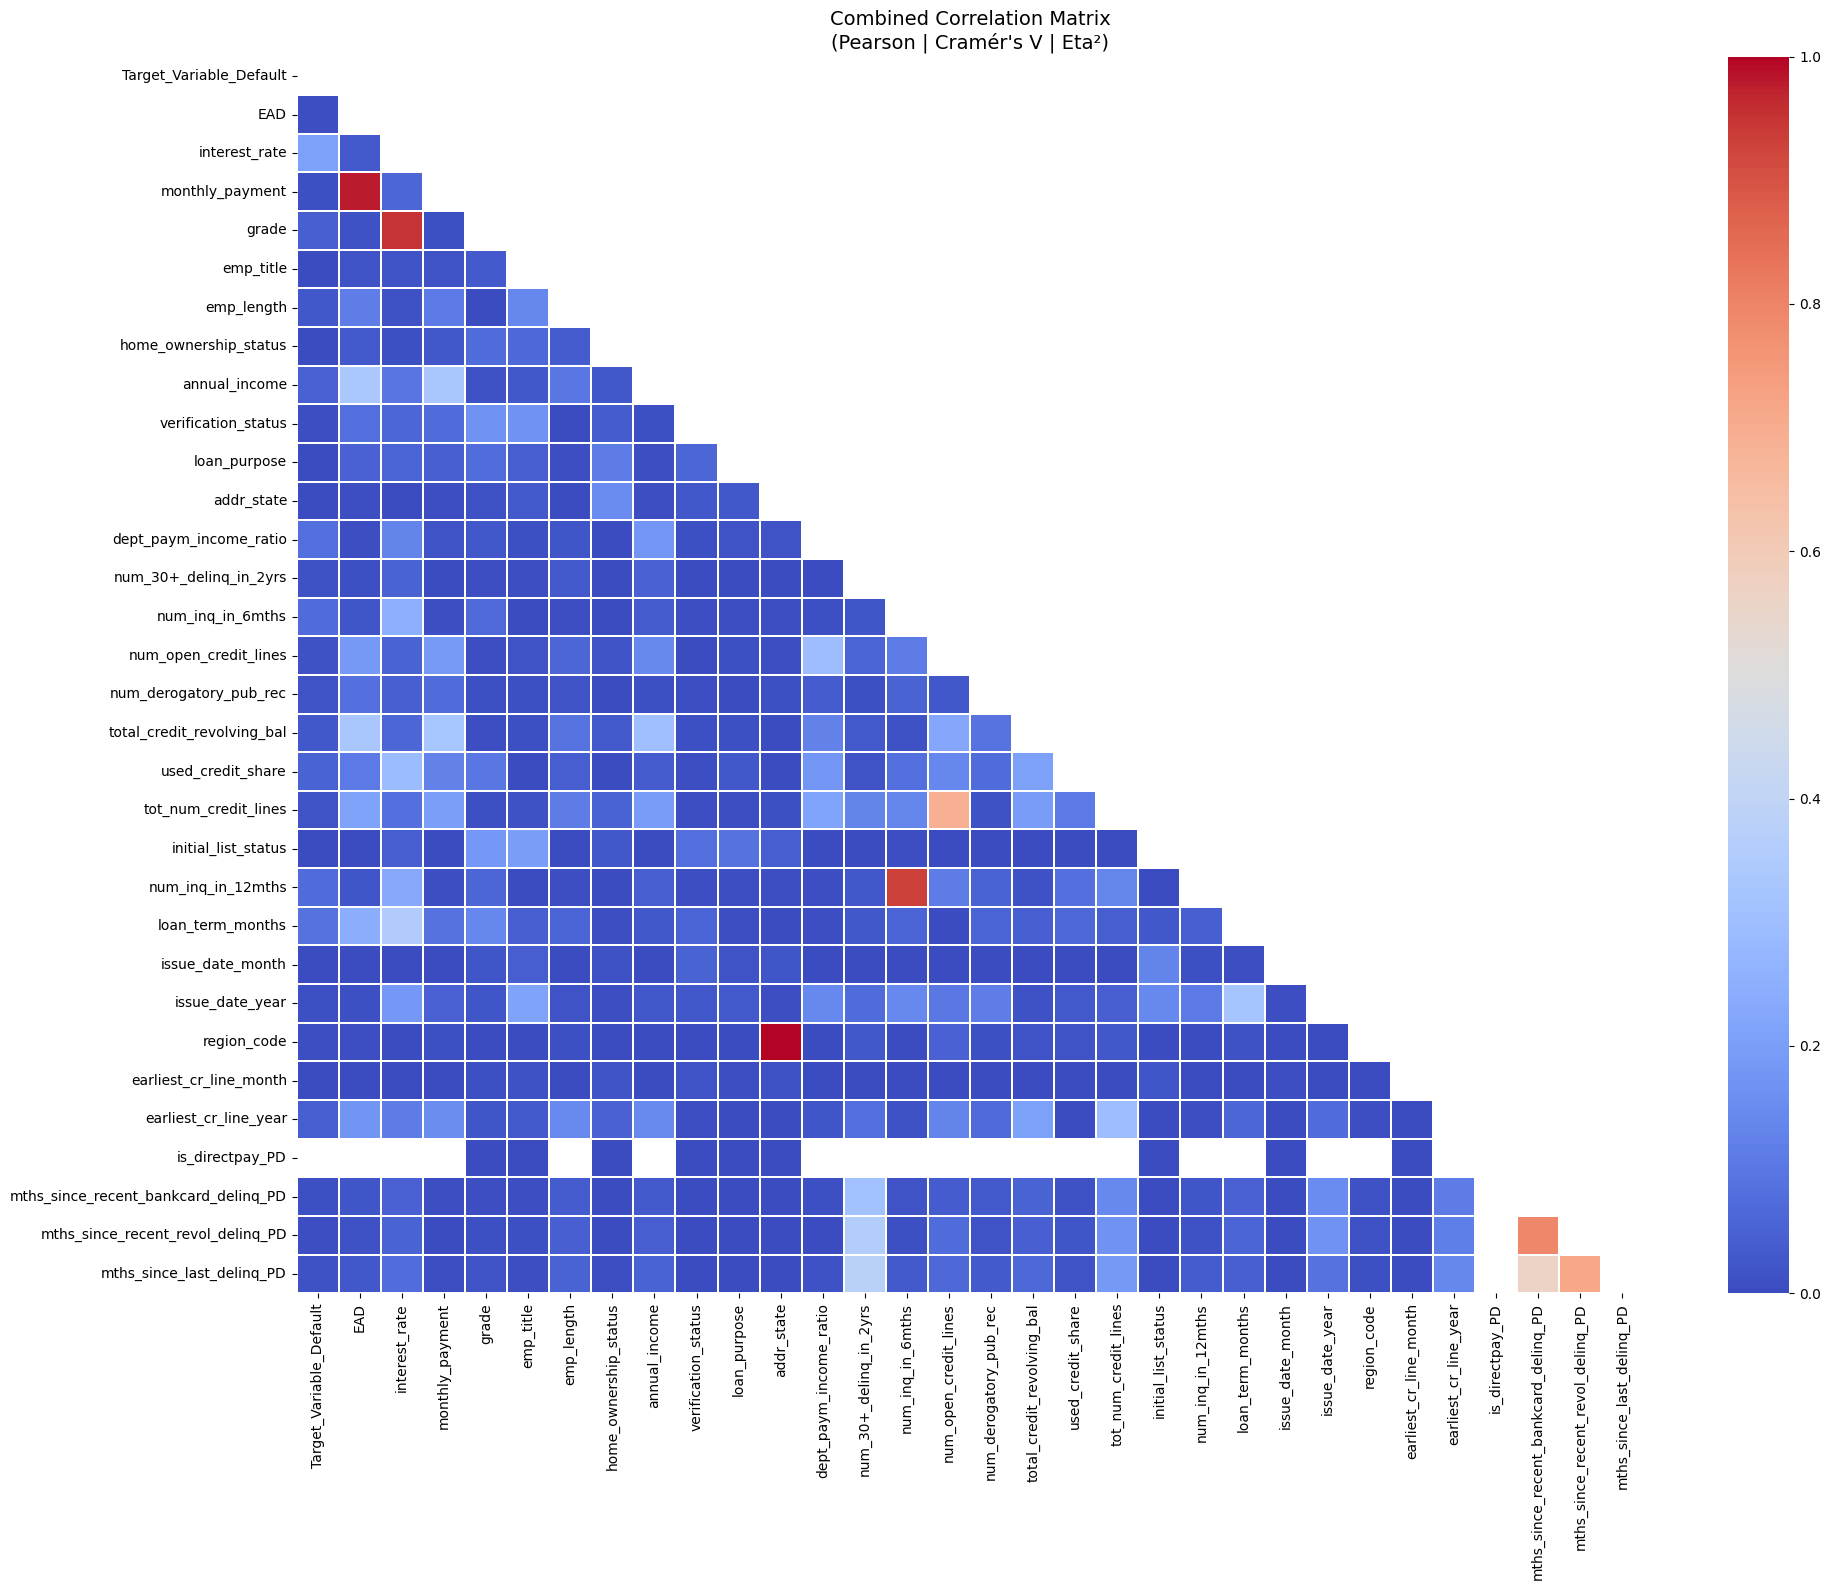

⚠ Pairs above threshold (0.75): 5
✓ Features recommended for removal: 5
  ['mths_since_recent_revol_delinq_PD', 'interest_rate', 'num_inq_in_6mths', 'EAD', 'addr_state']


,feature_a,feature_b,correlation,mi_feature_a,mi_feature_b,discard
0,addr_state,region_code,0.9984,0.0046,0.0112,addr_state
1,EAD,monthly_payment,0.9797,0.0069,0.0390,EAD
2,interest_rate,grade,0.9497,0.0236,0.0266,interest_rate
3,num_inq_in_6mths,num_inq_in_12mths,0.9325,0.0090,0.0091,num_inq_in_6mths
4,mths_since_recent_bankcard_delinq_PD,mths_since_recent_revol_delinq_PD,0.7897,0.0766,0.0745,mths_since_recent_revol_delinq_PD


In [9]:
# PD correlation matrix
corr_matrix_PD = compute_plot_correlation_matrix(dev[features_PD])
pairs_PD, to_drop_PD = analyze_correlated_pairs(corr_matrix_PD, report=report_PD, threshold=0.75)
pairs_PD

In [10]:
# EAD vs monthly_payment are highly correlated: monthly_payment captures debt burden more directly
# EAD is retained only for EL calculation, not as a predictive feature
features_PD = [col for col in features_PD if col not in to_drop_PD]

with open("data/processed/features_PD_AfterCorrelation.pkl", "wb") as f:
    pickle.dump(features_PD, f)

print(f"PD features after correlation filter: {len(features_PD)}")

PD features after correlation filter: 27


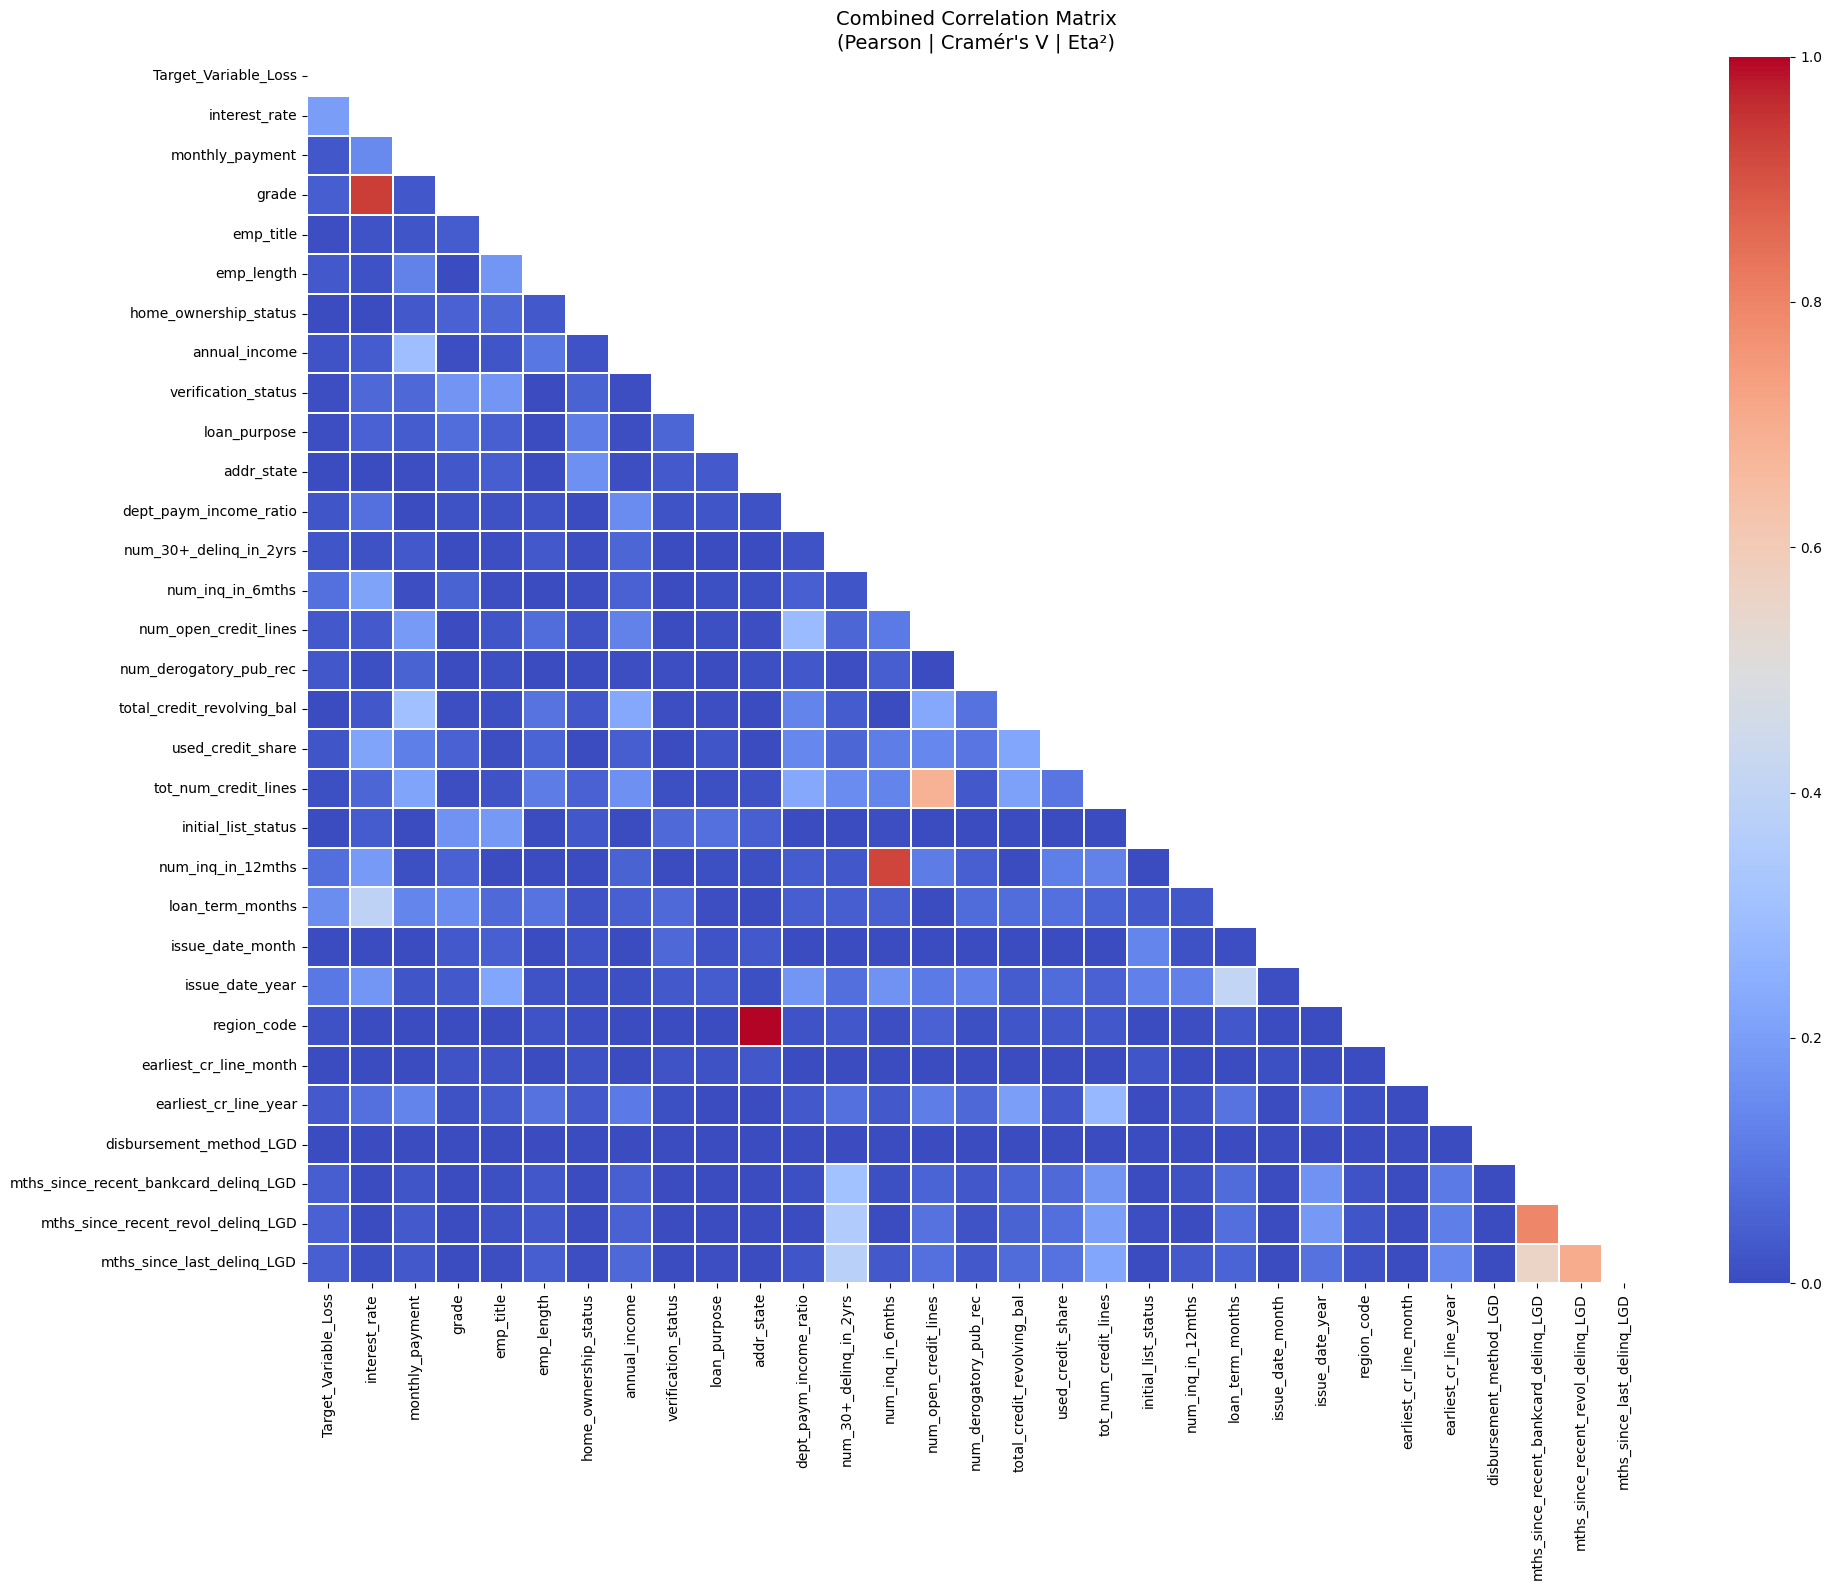

⚠ Pairs above threshold (0.75): 4
✓ Features recommended for removal: 4
  ['grade', 'region_code', 'num_inq_in_6mths', 'mths_since_recent_bankcard_delinq_LGD']


,feature_a,feature_b,correlation,mi_feature_a,mi_feature_b,discard
0,addr_state,region_code,0.9985,0.5602,0.4374,region_code
1,interest_rate,grade,0.9361,1.5950,0.9985,grade
2,num_inq_in_6mths,num_inq_in_12mths,0.9249,0.2670,0.2738,num_inq_in_6mths
3,mths_since_recent_bankcard_delinq_LGD,mths_since_recent_revol_delinq_LGD,0.7961,0.2395,0.3185,mths_since_recent_bankcard_delinq_LGD


In [11]:
# LGD correlation matrix
corr_matrix_LGD = compute_plot_correlation_matrix(dev_default[features_LGD])
pairs_LGD, to_drop_LGD = analyze_correlated_pairs(corr_matrix_LGD, report=report_LGD, threshold=0.75)
pairs_LGD

In [12]:
features_LGD = [col for col in features_LGD if col not in to_drop_LGD]

with open("data/processed/features_LGD_AfterCorrelation.pkl", "wb") as f:
    pickle.dump(features_LGD, f)

print(f"LGD features after correlation filter: {len(features_LGD)}")

LGD features after correlation filter: 27


## 5. Exploratory XGBoost Feature Selection

An exploratory XGBoost model is trained to rank features by SHAP importance and determine a cutoff, avoiding deep EDA on features with negligible predictive contribution.

Two parallel cutoff criteria are computed: gain-based (fast reference) and SHAP-based (primary criterion, no cardinality bias). The SHAP cutoff uses 80% cumulative importance for PD and 90% for LGD; the higher threshold for LGD reflects the flatter SHAP curve caused by the noisier continuous target and the smaller defaulted population.

### Leakage and survival bias exclusions

Besides the post-origination and vintage-dependent variables removed in section 2, the following features are excluded from the exploratory model despite potentially appearing predictive:
- `issue_date_year`, `issue_date_month`: survival bias. Even within matured cohorts, the issue date carries the economic cycle rather than borrower risk, and a model scored on recent vintages would extrapolate it.

→ Preparing data...


→ Sampling 500,000 rows from 676,113...


→ Training full exploratory model...


→ Full model: AUC: 0.6895 | Accuracy: 0.6259 | Precision: 0.2317 | Recall: 0.6539 | F1: 0.3421
→ Computing gain-based feature importance...
→ Computing SHAP values (sample: 50,000 rows)...


→ Gain-based cutoff:  12 features
→ SHAP-based cutoff:  10 features (primary criterion)


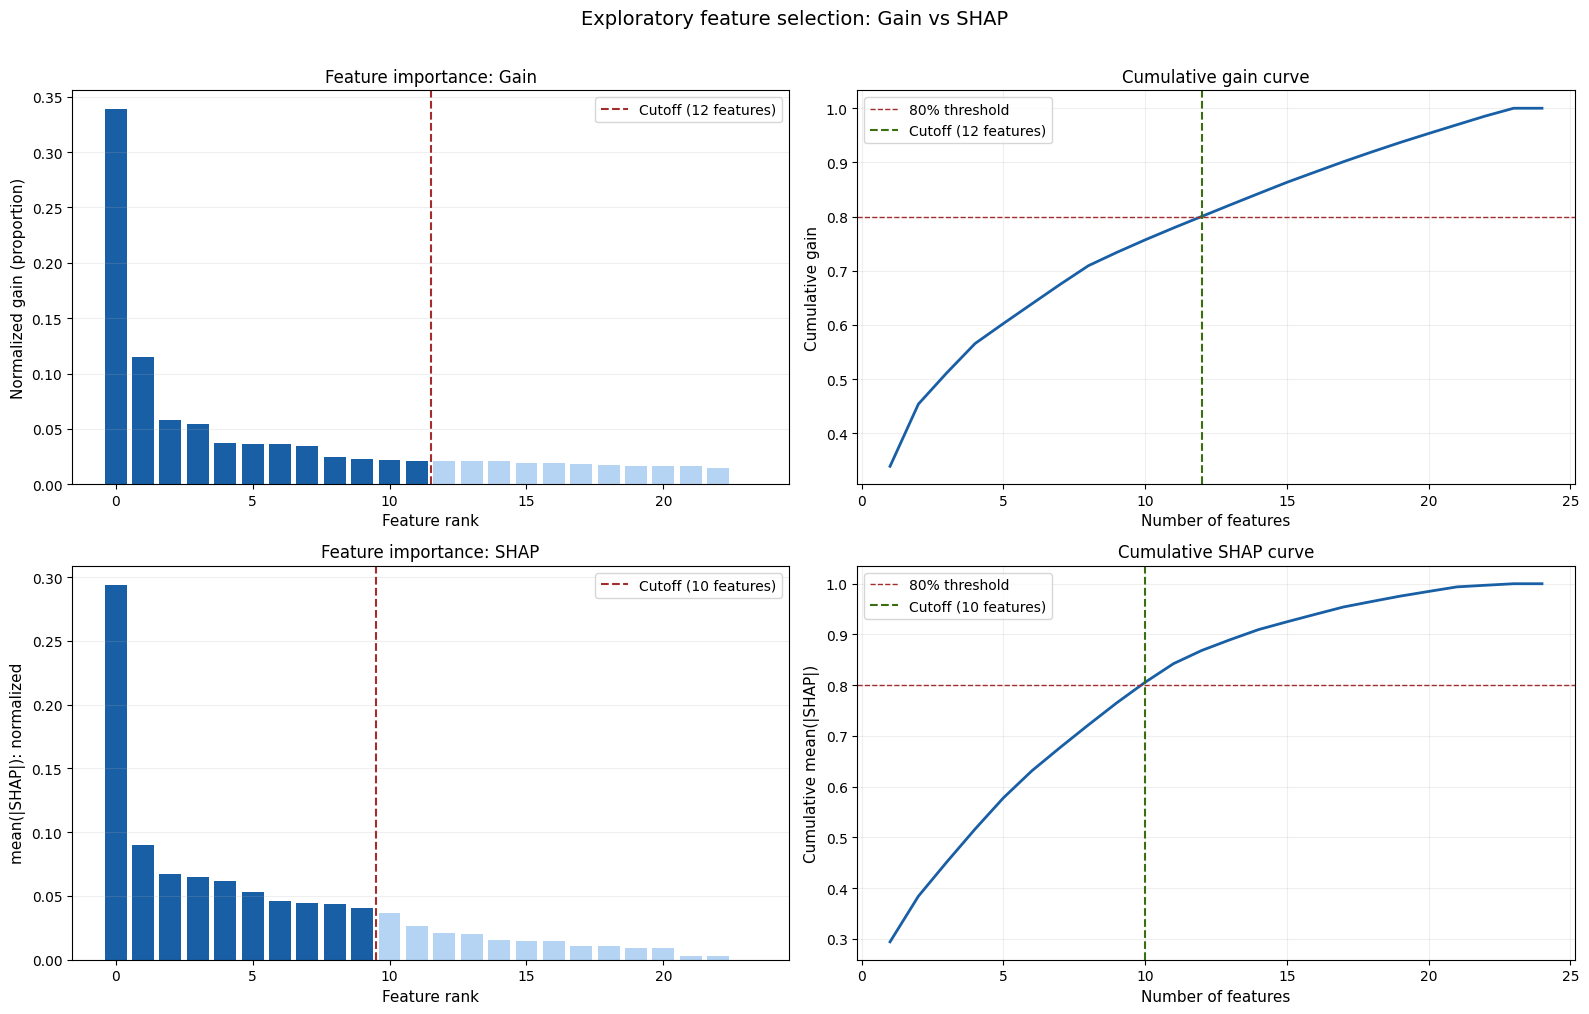

→ Generating SHAP summary plot...


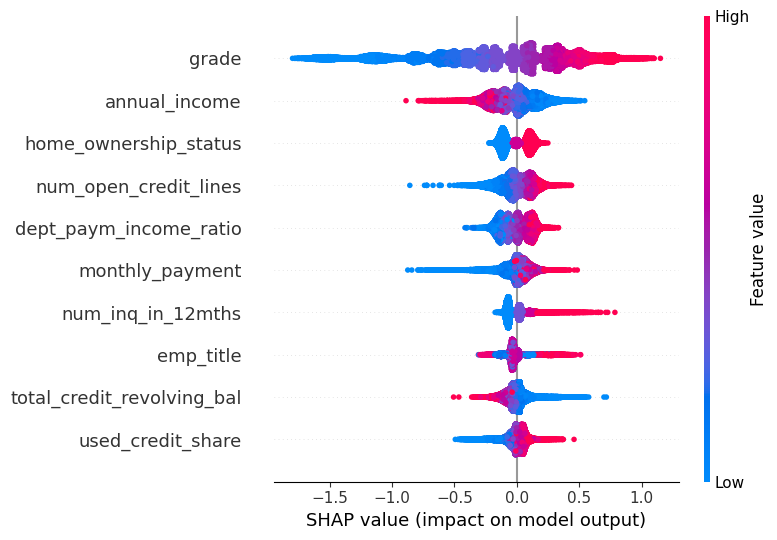


→ Validating reduced model (SHAP-based cutoff)...


  [10 features] AUC: 0.6828 | Accuracy: 0.6179 | Precision: 0.2272 | Recall: 0.6528 | F1: 0.3370 | Degradation: 0.0067

✓ Done. Selected 10 features (SHAP-based cutoff).
  Note: gain cutoff (12) and SHAP cutoff (10) diverged. Review importance_df to understand which features differ between criteria.
Selected PD features: 10
['grade', 'annual_income', 'home_ownership_status', 'num_open_credit_lines', 'dept_paym_income_ratio', 'monthly_payment', 'num_inq_in_12mths', 'emp_title', 'total_credit_revolving_bal', 'used_credit_share']


In [13]:
# PD exploratory model
# Post-origination variables (payments, recoveries, late fees) and issue date
leakage_vars_PD = [
    'princ_rec', 'interest_rec', 'remaining_princ_for_tot_amnt_fund',
    'paym_rec_for_tot_amnt_fund', 'has_late_fees_PD',
    'issue_date_year', 'issue_date_month', 'Target_Variable_Default'
]
features_PD_model = [f for f in features_PD if f not in leakage_vars_PD]

importance_df_PD, selected_features_PD, metrics_PD = exploratory_feature_selection(
    df=dev,
    features=features_PD_model,
    target='Target_Variable_Default',
    model_type='classification',
    sample_size=500_000
)

features_PD = selected_features_PD.copy()
print(f"Selected PD features: {len(features_PD)}")
print(features_PD)

In [14]:
# Gain vs SHAP divergence analysis
cutoff_gain = metrics_PD['cutoffs']['gain_based']
cutoff_shap = metrics_PD['cutoffs']['shap_based']

gain_selected = importance_df_PD.sort_values('gain', ascending=False).head(cutoff_gain)['feature'].tolist()
shap_selected = importance_df_PD.sort_values('shap_mean_abs', ascending=False).head(cutoff_shap)['feature'].tolist()

print("In gain but not SHAP:", [f for f in gain_selected if f not in shap_selected])
print("In SHAP but not gain:", [f for f in shap_selected if f not in gain_selected])

In gain but not SHAP: ['loan_term_months', 'verification_status', 'emp_length']
In SHAP but not gain: ['used_credit_share']


→ Preparing data...


→ Training full exploratory model...


→ Full model: RMSE: 22.6492 | MAE: 18.8686 | R²: 0.0636
→ Computing gain-based feature importance...
→ Computing SHAP values (sample: 20,118 rows)...


→ Gain-based cutoff:  19 features
→ SHAP-based cutoff:  16 features (primary criterion)


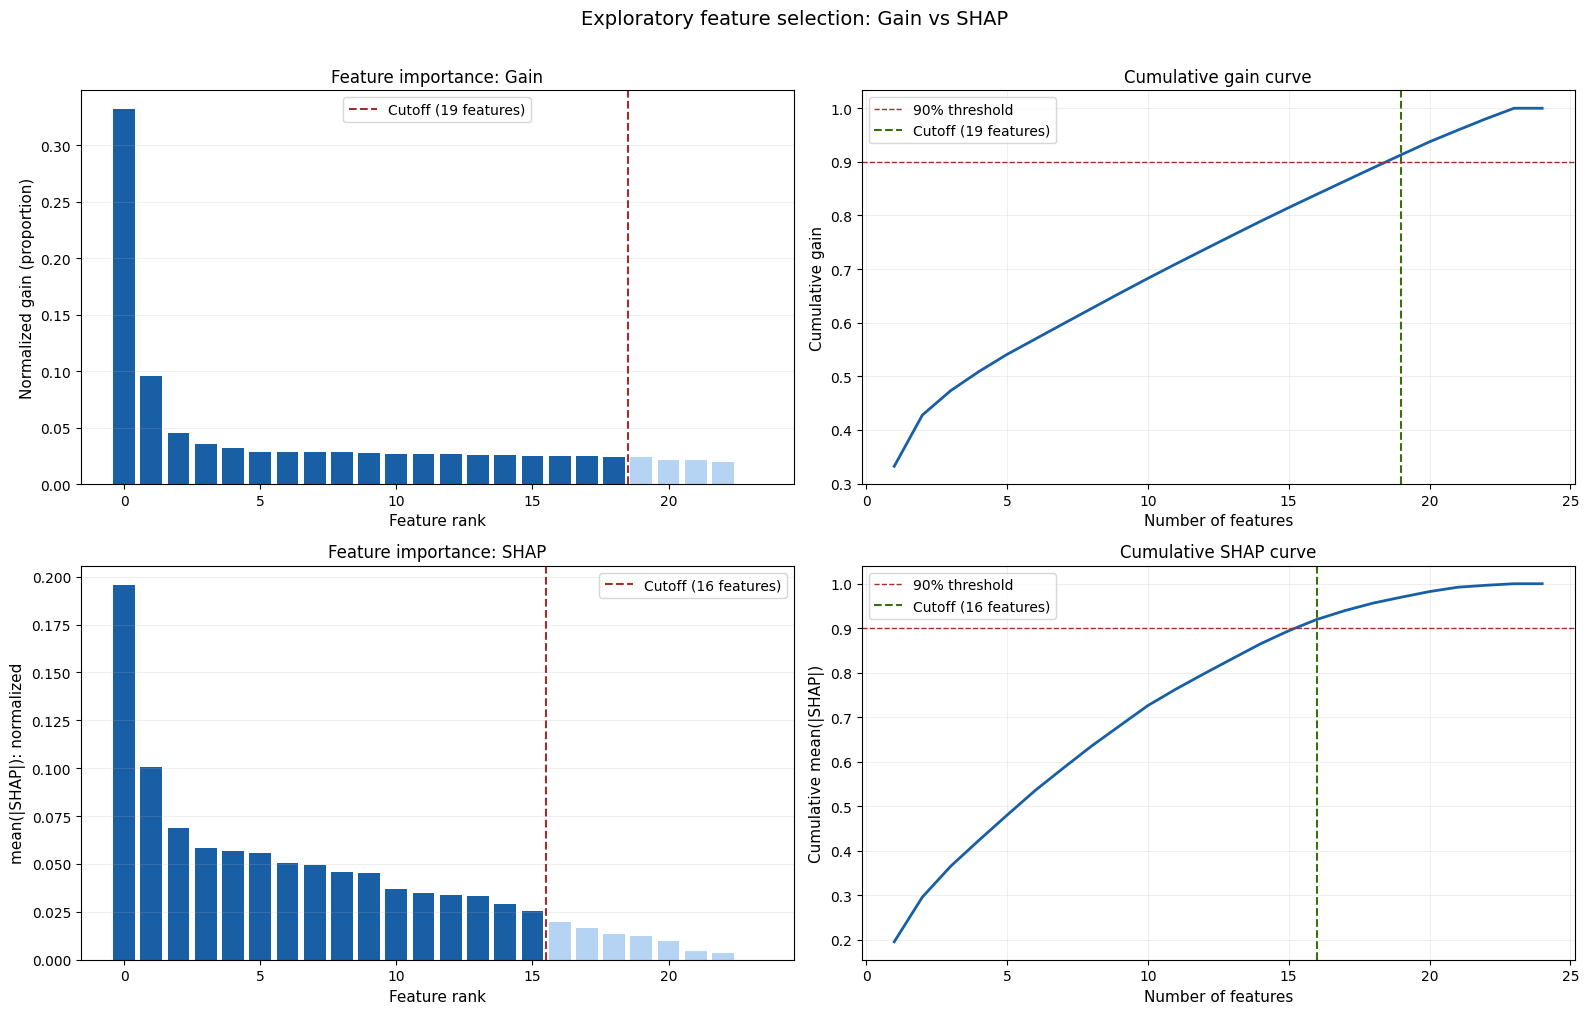

→ Generating SHAP summary plot...


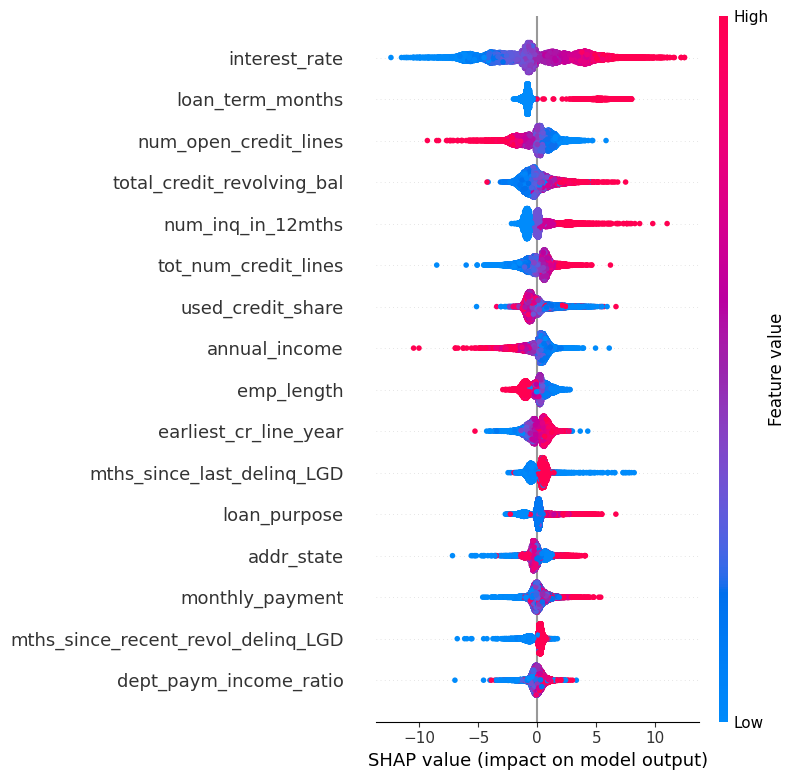


→ Validating reduced model (SHAP-based cutoff)...


  [16 features] RMSE: 22.6770 | MAE: 18.8873 | R²: 0.0613 | Degradation: 0.12%

✓ Done. Selected 16 features (SHAP-based cutoff).
  Note: gain cutoff (19) and SHAP cutoff (16) diverged. Review importance_df to understand which features differ between criteria.
Selected LGD features: 16
['interest_rate', 'loan_term_months', 'num_open_credit_lines', 'total_credit_revolving_bal', 'num_inq_in_12mths', 'tot_num_credit_lines', 'used_credit_share', 'annual_income', 'emp_length', 'earliest_cr_line_year', 'mths_since_last_delinq_LGD', 'loan_purpose', 'addr_state', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD', 'dept_paym_income_ratio']


In [15]:
# LGD exploratory model: threshold raised to 0.90 (see documentation)
# The LGD target is built from payments, recoveries and late fees, so every
# post-origination payment variable is excluded, not only the principal ones.
leakage_vars_LGD = [
    'princ_rec', 'interest_rec', 'remaining_princ_for_tot_amnt_fund',
    'paym_rec_for_tot_amnt_fund', 'late_fees_rec_LGD', 'has_late_fees_PD',
    'issue_date_year', 'issue_date_month', 'Target_Variable_Loss'
]
features_LGD_model = [f for f in features_LGD if f not in leakage_vars_LGD]

importance_df_LGD, selected_features_LGD, metrics_LGD = exploratory_feature_selection(
    df=dev_default,
    features=features_LGD_model,
    target='Target_Variable_Loss',
    model_type='regression',
    sample_size=120_000,
    cumulative_gain_threshold=0.90
)

# dept_paym_income_ratio added via expert judgment (Basel core metric with independent
# signal) when the SHAP cutoff has not already selected it
features_LGD = selected_features_LGD + [
    f for f in ["dept_paym_income_ratio"] if f not in selected_features_LGD
]
print(f"Selected LGD features: {len(features_LGD)}")
print(features_LGD)

## 6. Checkpoint: Save Feature Lists and Dataframe

In [16]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/checkpoint_DataFrame_for_EDA.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

with open("data/processed/features_PD_for_EDA.pkl", "wb") as f:
    pickle.dump(features_PD, f)

with open("data/processed/features_LGD_for_EDA.pkl", "wb") as f:
    pickle.dump(features_LGD, f)

print(f"Saved. PD features: {len(features_PD)} | LGD features: {len(features_LGD)}")

Saved. PD features: 10 | LGD features: 16


In [17]:
# Load checkpoints (skip re-running)
with open("data/processed/checkpoint_DataFrame_for_EDA.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

with open("data/processed/features_PD_for_EDA.pkl", "rb") as f:
    features_PD = pickle.load(f)

with open("data/processed/features_LGD_for_EDA.pkl", "rb") as f:
    features_LGD = pickle.load(f)